# 🔬 Лабораторная работа 2. Пространственная фильтрация, выделение границ и свёрточный слой в PyTorch

## Цель работы

Изучить математические основы и программную реализацию двумерной дискретной свёртки, освоить классические методы пространственной фильтрации и разобраться в устройстве свёрточного слоя `nn.Conv2d`:
- Реализовать двумерную свёртку вручную и сравнить её с `torch.nn.functional.conv2d`
- Применить классические ядра фильтрации (размытие, повышение резкости, операторы Собеля и Лапласа)
- Исследовать геометрию слоя `nn.Conv2d` (`kernel_size`, `stride`, `padding`, `dilation`, `groups`)
- Визуализировать обученные фильтры и карты признаков (Feature Maps) свёрточной сети

---

## Импорты и подготовка окружения

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import time

# Фиксируем seed для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Все библиотеки импортированы успешно ✅ (Устройство: {device})")

Все библиотеки импортированы успешно ✅ (Устройство: cpu)


### Вспомогательный датасет `ColorShapesDataset` из Лабораторной работы №1

Для экспериментов с фильтрами и выделением границ нам понадобятся как реальные изображения из **CIFAR-10**, так и синтетические геометрические фигуры из `ColorShapesDataset`, разработанного в первой лабораторной работе. Ниже приведена готовая реализация генератора фигур.

In [7]:
class ColorShapesDataset(Dataset):
    """
    Синтетический датасет с цветными геометрическими фигурами (из ЛР №1).
    Классы: 0 - circle (круг), 1 - square (квадрат), 2 - triangle (треугольник).
    """
    CLASSES = ['circle', 'square', 'triangle']

    def __init__(self, num_samples=300, image_size=64, transform=None, background_noise=40):
        self.num_samples = num_samples
        self.image_size = image_size
        self.transform = transform
        self.background_noise = background_noise
        self.labels = [i % len(self.CLASSES) for i in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def _generate_image(self, label):
        H = W = self.image_size
        img = np.random.randint(0, max(1, self.background_noise), (H, W, 3), dtype=np.uint8)
        color = np.random.randint(180, 256, 3, dtype=np.uint8)

        cx = np.random.randint(H // 3, 2 * H // 3)
        cy = np.random.randint(W // 3, 2 * W // 3)
        size = np.random.randint(H // 5, H // 3)

        yy, xx = np.ogrid[:H, :W]

        if label == 0:  # circle
            mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= size ** 2
        elif label == 1:  # square
            mask = (np.abs(xx - cx) <= size) & (np.abs(yy - cy) <= size)
        else:  # triangle
            dy = yy - (cy - size)
            half_width = (dy * size) / (2 * size + 1e-5)
            mask = (dy >= 0) & (dy <= 2 * size) & (np.abs(xx - cx) <= half_width)

        img[mask] = color
        return Image.fromarray(img)

    def __getitem__(self, idx):
        label = self.labels[idx]
        rng_state = np.random.get_state()
        np.random.seed(idx + 100)
        image = self._generate_image(label)
        np.random.set_state(rng_state)

        if self.transform:
            image = self.transform(image)
        return image, label


# Создадим экземпляр датасета для работы
shapes_dataset = ColorShapesDataset(
    num_samples=100, image_size=64, transform=transforms.ToTensor()
)
print(f"ColorShapesDataset готов: {len(shapes_dataset)} изображений, форма: {shapes_dataset[0][0].shape}")

ColorShapesDataset готов: 100 изображений, форма: torch.Size([3, 64, 64])


---
## Задание 1. Двумерная свёртка: от цикла до тензорной операции

Двумерная дискретная свёртка (точнее — взаимная корреляция, используемая в фреймворках глубокого обучения) для одноканального изображения $I$ и ядра $K$ размера $k_H \times k_W$ определяется формулой:

$$Y(i, j) = \sum_{m=0}^{k_H - 1} \sum_{n=0}^{k_W - 1} I(i \cdot s + m, \, j \cdot s + n) \cdot K(m, n)$$

где $s$ — шаг свёртки (`stride`), а к исходному изображению предварительно добавлены нулевые границы ширины $p$ (`padding`).

### 1.1. Реализуйте двумерную свёртку вручную

Напишите функцию `conv2d_manual(image, kernel, padding=0, stride=1)` для одноканального двумерного тензора `image` формы `(H, W)` и ядра `kernel` формы `(kH, kW)`.

In [8]:
# === ЗАДАНИЕ 1.1 ===

def conv2d_manual(image: torch.Tensor, kernel: torch.Tensor, padding: int = 0, stride: int = 1) -> torch.Tensor:
    """
    Выполняет 2D-свёртку (cross-correlation) одноканального изображения с ядром kernel.

    Args:
        image: 2D тензор (H, W)
        kernel: 2D тензор (kH, kW)
        padding: величина нулевого паддинга вокруг изображения
        stride: шаг движения окна свёртки

    Returns:
        torch.Tensor: 2D тензор результата свёртки (H_out, W_out)
    """
    H, W = image.shape
    kH, kW = kernel.shape

    # Реализуйте функцию
    # Подсказка:
    # 1. Если padding > 0, используйте F.pad(image, (padding, padding, padding, padding))
    if padding > 0:
        image = F.pad(image, (padding, padding, padding, padding))
    # 2. Вычислите выходные размеры:
    #    H_out = (H + 2 * padding - kH) // stride + 1
    #    W_out = (W + 2 * padding - kW) // stride + 1
    H_out = (H + 2 * padding - kH) // stride + 1
    W_out = (W + 2 * padding - kW) // stride + 1
    # 3. Создайте выходной тензор torch.zeros((H_out, W_out), dtype=image.dtype)
    output = torch.zeros((H_out, W_out), dtype=image.dtype)
    # 4. В двойном цикле по i и j вырезайте окно из изображения,
    #    умножайте поэлементно на kernel и суммируйте (.sum())
    for i in range(H_out):
        for j in range(W_out):
            window = image[i * stride:i * stride + kH, j * stride:j * stride + kW]
            output[i, j] = (window * kernel).sum()
    return output


# Простая проверка на тестовом тензоре 5x5
test_img = torch.arange(25, dtype=torch.float32).reshape(5, 5)
test_kernel = torch.ones((3, 3), dtype=torch.float32)
print(conv2d_manual(test_img, test_kernel, padding=1, stride=1))

tensor([[ 12.,  21.,  27.,  33.,  24.],
        [ 33.,  54.,  63.,  72.,  51.],
        [ 63.,  99., 108., 117.,  81.],
        [ 93., 144., 153., 162., 111.],
        [ 72., 111., 117., 123.,  84.]])


### 1.2. Сверьте результат с `torch.nn.functional.conv2d`

1. Возьмите одно изображение из `shapes_dataset` и переведите его в оттенки серого (усреднив по канальной размерности: `img_gray = img.mean(dim=0)`).
2. Примените к нему вашу функцию `conv2d_manual` и встроенную функцию `F.conv2d` с одним и тем же ядром $3 \times 3$ (при `padding=1, stride=1`).
3. Выведите максимальную абсолютную разницу между результатами и убедитесь, что `torch.allclose(..., atol=1e-5)` возвращает `True`.

> **Важно:** `F.conv2d` ожидает на вход 4D-тензоры: изображение формы `(B, C_in, H, W)` и ядро формы `(C_out, C_in, kH, kW)`. Используйте `.unsqueeze(0).unsqueeze(0)` для добавления размерностей батча и канала.

In [9]:
# === ЗАДАНИЕ 1.2 ===

# 1. Получите изображение из shapes_dataset и переведите в 2D grayscale (64, 64)
img_rgb, label = shapes_dataset[0]
img_gray = img_rgb.mean(dim=0)

# 2. Задайте произвольное ядро 3x3
kernel = torch.tensor([[1.0, 0.0, -1.0],
                        [2.0, 0.0, -2.0],
                        [1.0, 0.0, -1.0]])

# 3. Вычислите результат через conv2d_manual и через F.conv2d
out_manual = conv2d_manual(img_gray, kernel, padding=1, stride=1)
out_torch = F.conv2d(img_gray.unsqueeze(0).unsqueeze(0), kernel.unsqueeze(0).unsqueeze(0), padding=1, stride=1).squeeze()

# 4. Выведите максимальную разницу и результат torch.allclose
print(f"Максимальная разница: {torch.max(torch.abs(out_manual - out_torch))}")
print(f"Результат torch.allclose: {torch.allclose(out_manual, out_torch)}")

Максимальная разница: 2.384185791015625e-07
Результат torch.allclose: False


### 1.3. Замерьте скорость: ручная реализация vs `F.conv2d`

Сравните время фильтрации изображений с помощью вашей функции `conv2d_manual` и оптимизированной `F.conv2d` для ядер размера $3 \times 3$, $5 \times 5$ и $7 \times 7$. Результат оформите в виде таблицы.

In [10]:
# === ЗАДАНИЕ 1.3 ===

def benchmark_conv(image_2d, kernel_size, n_runs=10):
    """
    Сравнивает время работы conv2d_manual и F.conv2d в миллисекундах.
    """
    kernel_2d = torch.randn(kernel_size, kernel_size)
    pad = kernel_size // 2

    # Замер ручной свёртки
    start = time.time()
    for _ in range(n_runs):
        _ = conv2d_manual(image_2d, kernel_2d, padding=pad)
    t_manual = (time.time() - start) / n_runs * 1000

    # Замер F.conv2d
    img_4d = image_2d.unsqueeze(0).unsqueeze(0)
    kernel_4d = kernel_2d.unsqueeze(0).unsqueeze(0)
    start = time.time()
    for _ in range(n_runs):
        _ = F.conv2d(img_4d, kernel_4d, padding=pad)
    t_torch = (time.time() - start) / n_runs * 1000

    return t_manual, t_torch

# Проведите замеры для kernel_size in [3, 5, 7] на изображении 64x64
# Выведите таблицу:
print("kernel_size | Manual (мс) | F.conv2d (мс) | Ускорение (раз)")
print("-" * 60)
# Ваш код здесь
for kernel_size in [3, 5, 7]:
    t_manual, t_torch = benchmark_conv(img_gray, kernel_size)
    speedup = t_manual / t_torch if t_torch > 0 else float('inf')
    print(f"{kernel_size:^12} | {t_manual:>12.4f} | {t_torch:>12.4f} | {speedup:>14.2f}")

kernel_size | Manual (мс) | F.conv2d (мс) | Ускорение (раз)
------------------------------------------------------------
     3       |      13.5757 |       0.0092 |        1478.98
     5       |      13.7563 |       0.1734 |          79.34
     7       |      13.5144 |       0.0315 |         428.77


---
## Задание 2. Классические фильтры и выделение границ

В классической обработке изображений ядра свёртки конструируются математически для решения конкретных задач: подавления шума, повышения резкости или поиска перепадов яркости (границ объектов).

### 2.1. Создайте банк классических ядер фильтрации

Задайте словарь `FILTERS`, содержащий следующие 2D-тензоры размера $3 \times 3$ (`dtype=torch.float32`):

1. **Box Blur (усредняющий фильтр):** все элементы равны $\frac{1}{9}$.
2. **Gaussian Blur (гауссово размытие $3 \times 3$):**
   $$\frac{1}{16}\begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix}$$
3. **Sharpen (повышение резкости):**
   $$\begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$$
4. **Sobel X (вертикальные границы — производная по $x$):**
   $$\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$$
5. **Sobel Y (горизонтальные границы — производная по $y$):**
   $$\begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$$
6. **Laplacian (оператор Лапласа — вторая производная):**
   $$\begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}$$

In [11]:
# === ЗАДАНИЕ 2.1 ===

# Заполните словарь FILTERS тензорами размера (3, 3)
FILTERS = {
    'box_blur': torch.ones((3, 3)) / 9.0,
    'gaussian_blur': torch.tensor([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16.0,
    'sharpen': torch.tensor([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]) / 9.0,
    'sobel_x': torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    'sobel_y': torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    'laplacian': torch.tensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
}


# Проверьте суммы элементов каждого ядра
# for name, k in FILTERS.items():
#     print(f"{name:>15}: shape={tuple(k.shape)}, sum={k.sum().item():.2f}")
for name, k in FILTERS.items():
    print(f"{name:>15}: shape={tuple(k.shape)}, sum={k.sum().item():.2f}")


       box_blur: shape=(3, 3), sum=1.00
  gaussian_blur: shape=(3, 3), sum=1.00
        sharpen: shape=(3, 3), sum=0.11
        sobel_x: shape=(3, 3), sum=0.00
        sobel_y: shape=(3, 3), sum=0.00
      laplacian: shape=(3, 3), sum=0.00


### 2.2. Детектирование контуров и градиентов на `ColorShapesDataset`

Примените операторы Собеля $G_x$ (`sobel_x`) и $G_y$ (`sobel_y`) к трём фигурам разных классов (`circle`, `square`, `triangle`) из `shapes_dataset`.

Для каждой фигуры вычислите:
- Отклик по горизонтали $G_x$ и по вертикали $G_y$
- **Магнитуду (модуль) градиента:** $G = \sqrt{G_x^2 + G_y^2 + \varepsilon}$ (где $\varepsilon = 10^{-8}$)
- **Направление градиента (угол):** $\theta = \operatorname{atan2}(G_y, G_x)$ в диапазоне $[-\pi, \pi]$

Визуализируйте сетку $3 \times 5$:
`Оригинал | Gx (верт. границы) | Gy (гориз. границы) | Магнитуда G | Направление градиента`

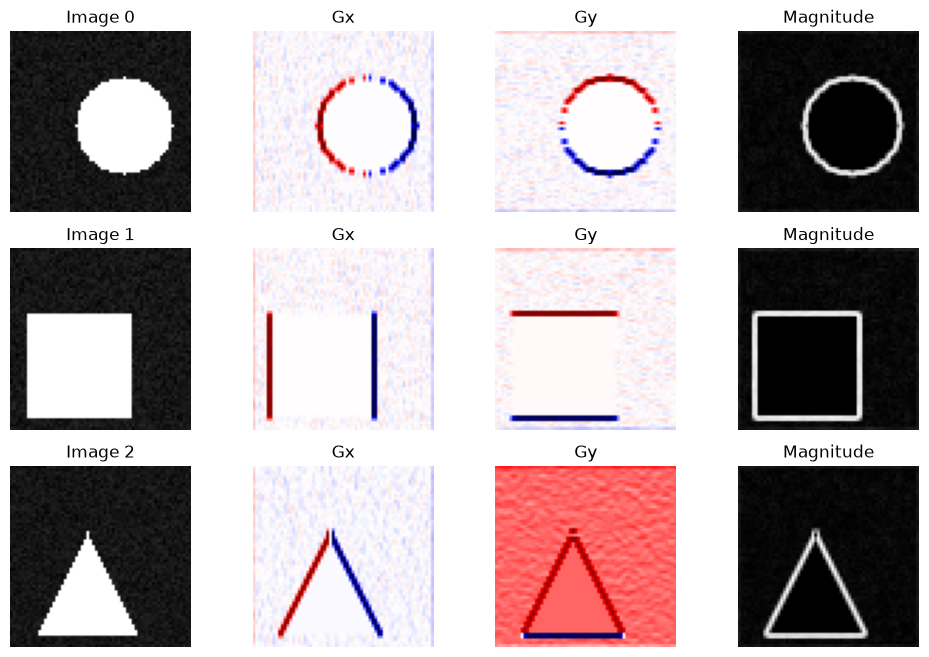

In [12]:
# === ЗАДАНИЕ 2.2 ===

def analyze_edges(dataset, sample_indices=(0, 1, 2)):
    """
    Визуализирует работу оператора Собеля (Gx, Gy, магнитуда и угол градиента)
    для выбранных изображений из датасета.
    """
    # Реализуйте функцию
    # Подсказка:
    # 1. Подготовьте ядра sobel_x и sobel_y формы (1, 1, 3, 3)
    sobbel_x = FILTERS['sobel_x'].float().unsqueeze(0).unsqueeze(0)
    sobbel_y = FILTERS['sobel_y'].float().unsqueeze(0).unsqueeze(0)
    # 2. Для каждого индекса переведите изображение в grayscale: (1, 1, H, W)
    gray_images = []
    for idx in sample_indices:
        img_rgb, _ = dataset[idx]
        gray = img_rgb.mean(dim=0, keepdim=True).unsqueeze(0)  # (1, 1, H, W)
        gray_images.append(gray)
    # 3. Вычислите gx = F.conv2d(gray, sobel_x, padding=1) и gy = F.conv2d(gray, sobel_y, padding=1)
    gx_list = [F.conv2d(gray, sobbel_x, padding=1) for gray in gray_images]
    gy_list = [F.conv2d(gray, sobbel_y, padding=1) for gray in gray_images]
    # 4. Вычислите mag = torch.sqrt(gx**2 + gy**2 + 1e-8) и angle = torch.atan2(gy, gx)
    mag_list = [torch.sqrt(gx**2 + gy**2 + 1e-8) for gx, gy in zip(gx_list, gy_list)]
    angle_list = [torch.atan2(gy, gx) for gx, gy in zip(gx_list, gy_list)]
    # 5. Для отображения gx и gy удобно использовать cmap='seismic' или 'RdBu',
    #    для магнитуды — cmap='gray' или 'magma', для угла — cmap='hsv'
    plt.figure(figsize=(12, 8))
    for i, idx in enumerate(sample_indices):
        plt.subplot(len(sample_indices), 4, i * 4 + 1)
        plt.imshow(gray_images[i].squeeze(), cmap='gray')
        plt.title(f"Image {idx}")
        plt.axis('off')

        plt.subplot(len(sample_indices), 4, i * 4 + 2)
        plt.imshow(gx_list[i].squeeze(), cmap='seismic')
        plt.title("Gx")
        plt.axis('off')

        plt.subplot(len(sample_indices), 4, i * 4 + 3)
        plt.imshow(gy_list[i].squeeze(), cmap='seismic')
        plt.title("Gy")
        plt.axis('off')

        plt.subplot(len(sample_indices), 4, i * 4 + 4)
        plt.imshow(mag_list[i].squeeze(), cmap='gray')
        plt.title("Magnitude")
        plt.axis('off')
    plt.show()


analyze_edges(shapes_dataset, sample_indices=[0, 1, 2])

### 2.3. Поканальная фильтрация цветных изображений CIFAR-10 (`groups=3`)

Если мы хотим применить один и тот же 2D-фильтр (например, размытие или повышение резкости) **независимо к каждому из 3 цветовых каналов (R, G, B)**, в `F.conv2d` используется параметр `groups=3`.

При этом вес фильтра дублируется до формы `(3, 1, kH, kW)`:
`kernel_rgb = kernel_2d.unsqueeze(0).unsqueeze(0).repeat(3, 1, 1, 1)`

1. Загрузите датасет CIFAR-10.
2. Примените к нескольким цветным изображениям фильтры `gaussian_blur`, `sharpen` и `laplacian` поканально (`groups=3`).
3. Не забудьте ограничить значения пикселей диапазоном $[0, 1]$ с помощью `.clamp(0, 1)` перед визуализацией.

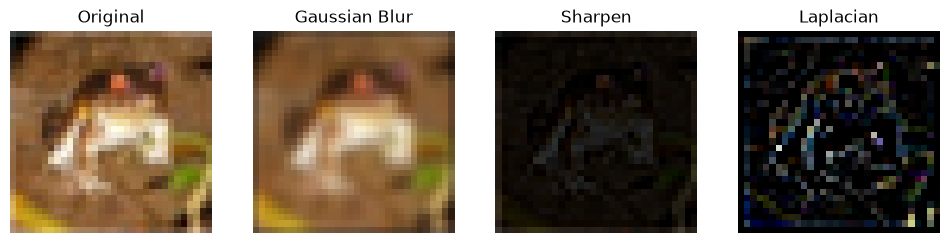

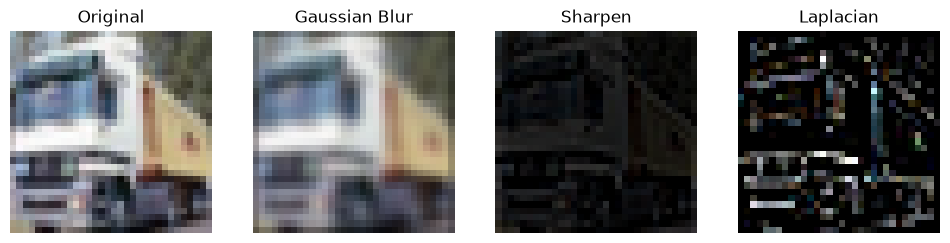

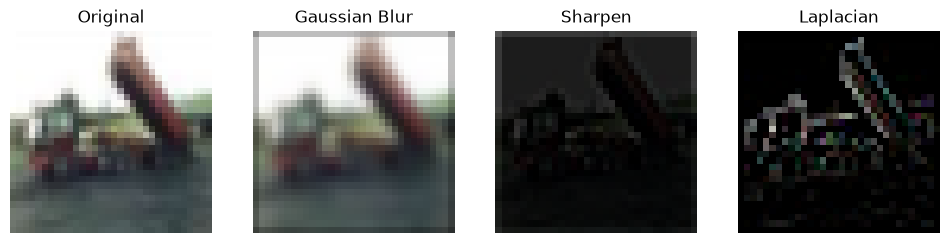

In [20]:
# === ЗАДАНИЕ 2.3 ===

# Загрузите CIFAR-10
cifar_dataset = torchvision.datasets.CIFAR10(
    root='../data', train=True, download=True, transform=transforms.ToTensor()
)

def apply_filter_rgb(img_tensor: torch.Tensor, kernel_2d: torch.Tensor) -> torch.Tensor:
    """
    Применяет 2D-фильтр поканально к RGB-изображению (3, H, W).

    Returns:
        torch.Tensor: отфильтрованное изображение (3, H, W), зажатое в [0, 1]
    """
    # Реализуйте функцию через F.conv2d(..., groups=3, padding=kernel_2d.shape[0]//2)
    return F.conv2d(img_tensor.unsqueeze(0), kernel_2d.unsqueeze(0).unsqueeze(0).repeat(3, 1, 1, 1), groups=3, padding=kernel_2d.shape[0]//2).squeeze(0).clamp(0, 1)

# Визуализируйте для 3 изображений из CIFAR-10:
# Оригинал | Gaussian Blur | Sharpen | Laplacian

target_filters = ['gaussian_blur', 'sharpen', 'laplacian']

# Визуализация для 3 изображений из CIFAR-10
for idx in [0, 1, 2]:
    img_rgb, label = cifar_dataset[idx]
    plt.figure(figsize=(12, 3))

    # 1. Оригинальное изображение
    plt.subplot(1, 4, 1)
    plt.imshow(img_rgb.permute(1, 2, 0))
    plt.title("Original")
    plt.axis('off')

    # 2. Отфильтрованные изображения
    for i, name in enumerate(target_filters):
        kernel = FILTERS[name]
        filtered_img = apply_filter_rgb(img_rgb, kernel.float())

        plt.subplot(1, 4, i + 2) # i равно 0, 1, 2 -> позиции 2, 3, 4
        plt.imshow(filtered_img.permute(1, 2, 0))
        plt.title(name.replace('_', ' ').title())
        plt.axis('off')

    plt.show()


---
## Задание 3. Геометрия и устройство слоя `nn.Conv2d`

В нейронных сетях ядра фильтрации не задаются вручную, а являются обучаемыми параметрами слоя `torch.nn.Conv2d`.

Выходной пространственный размер $(H_{out}, W_{out})$ свёрточного слоя вычисляется по формуле:

$$H_{out} = \left\lfloor \frac{H_{in} + 2 \cdot \text{padding} - \text{dilation} \cdot (\text{kernel\_size} - 1) - 1}{\text{stride}} + 1 \right\rfloor$$

### 3.1. Проверка формулы размерности выхода

1. Реализуйте функцию `calc_conv_out_shape(h_in, w_in, kernel_size, stride=1, padding=0, dilation=1)`.
2. Создайте тестовый батч формы `(16, 3, 32, 32)` (как в CIFAR-10) и протестируйте 5 различных конфигураций `nn.Conv2d`, сверив теоретический расчёт с фактическим `out.shape`.

In [21]:
# === ЗАДАНИЕ 3.1 ===

def calc_conv_out_shape(h_in, w_in, kernel_size, stride=1, padding=0, dilation=1):
    """
    Вычисляет (H_out, W_out) по теоретической формуле для Conv2d.
    """
    # Реализуйте формулу
    h_out = (h_in + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1
    w_out = (w_in + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1
    return h_out, w_out
    pass


# Конфигурации для проверки: (out_channels, kernel_size, stride, padding, dilation)
configs = [
    (16, 3, 1, 1, 1),  # Сохранение размера (Same padding)
    (16, 3, 1, 0, 1),  # Без паддинга (Valid)
    (32, 3, 2, 1, 1),  # Даунсэмплинг в 2 раза (Stride=2)
    (32, 5, 1, 2, 1),  # Ядро 5x5 с сохранением размера
    (64, 3, 1, 2, 2),  # Разреженная свёртка (Dilated convolution, dilation=2)
]

# Прогоните тестовый батч x = torch.randn(16, 3, 32, 32) через каждую конфигурацию,
# сверьте calc_conv_out_shape с реальным выходом nn.Conv2d и выведите таблицу.

x = torch.randn(16, 3, 32, 32)
for out_channels, kernel_size, stride, padding, dilation in configs:
    h_out, w_out = calc_conv_out_shape(32, 32, kernel_size, stride, padding, dilation)
    conv = nn.Conv2d(3, out_channels, kernel_size, stride=stride, padding=padding, dilation=dilation)
    y = conv(x)
    print(f"Config: {out_channels}, {kernel_size}, {stride}, {padding}, {dilation}")
    print(f"Calculated: ({h_out}, {w_out})")
    print(f"Actual: ({y.shape[2]}, {y.shape[3]})")
    print()


Config: 16, 3, 1, 1, 1
Calculated: (32, 32)
Actual: (32, 32)

Config: 16, 3, 1, 0, 1
Calculated: (30, 30)
Actual: (30, 30)

Config: 32, 3, 2, 1, 1
Calculated: (16, 16)
Actual: (16, 16)

Config: 32, 5, 1, 2, 1
Calculated: (32, 32)
Actual: (32, 32)

Config: 64, 3, 1, 2, 2
Calculated: (32, 32)
Actual: (32, 32)



### 3.2. Анализ параметров многоканального свёрточного слоя

В стандартном слое `nn.Conv2d(in_channels, out_channels, kernel_size, bias=True, groups=1)` каждый из `out_channels` фильтров имеет собственное 3D-ядро размера `(in_channels, kH, kW)` и одно скалярное смещение `bias`.

Напишите функцию `inspect_conv_layer(conv_layer)`, которая выводит:
- Форму тензора весов (`conv_layer.weight.shape`)
- Форму вектора смещений (`conv_layer.bias.shape`, если `bias=True`)
- Теоретическое число параметров по формуле
- Фактическое число обучаемых параметров через `sum(p.numel() for p in conv_layer.parameters())`

Сравните обычный слой `nn.Conv2d(32, 64, kernel_size=3)` и **Depthwise-слой** `nn.Conv2d(32, 32, kernel_size=3, groups=32)`.

In [23]:
# === ЗАДАНИЕ 3.2 ===

def inspect_conv_layer(conv: nn.Conv2d):
    """
    Анализирует структуру и количество параметров слоя nn.Conv2d.
    """
    # Реализуйте функцию
    # Подсказка: учтите случай groups > 1 в теоретической формуле:
    # N_weights = out_channels * (in_channels // groups) * kH * kW
    # 1. Форма тензора весов
    weight_shape = conv.weight.shape

    # 2. Форма вектора смещений (если bias=True)
    bias_shape = conv.bias.shape if conv.bias is not None else None

    # 3. Теоретическое число параметров с учётом groups[cite: 3]
    kH, kW = conv.kernel_size if isinstance(conv.kernel_size, tuple) else (conv.kernel_size, conv.kernel_size)
    n_weights = conv.out_channels * (conv.in_channels // conv.groups) * kH * kW
    n_bias = conv.out_channels if conv.bias is not None else 0
    theoretical_params = n_weights + n_bias

    # 4. Фактическое число обучаемых параметров[cite: 3]
    actual_params = sum(p.numel() for p in conv.parameters())

    return {
        'weight_shape': weight_shape,
        'bias_shape': bias_shape,
        'theoretical_params': theoretical_params,
        'actual_params': actual_params
    }

# Сравните три слоя:
# 1. Стандартная свёртка: nn.Conv2d(32, 64, kernel_size=3, padding=1)
# 2. Точечная свёртка 1x1 (Pointwise): nn.Conv2d(32, 64, kernel_size=1)
# 3. Поканальная свёртка (Depthwise): nn.Conv2d(32, 32, kernel_size=3, padding=1, groups=32)
lisyers = [
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.Conv2d(32, 64, kernel_size=1),
    nn.Conv2d(32, 32, kernel_size=3, padding=1, groups=32)
]

for i, conv in enumerate(lisyers):
    info = inspect_conv_layer(conv)
    print(f"Layer {i + 1}:")
    print(f"  Weight shape: {info['weight_shape']}")
    print(f"  Bias shape: {info['bias_shape']}")
    print(f"  Theoretical params: {info['theoretical_params']}")
    print(f"  Actual params: {info['actual_params']}")

Layer 1:
  Weight shape: torch.Size([64, 32, 3, 3])
  Bias shape: torch.Size([64])
  Theoretical params: 18496
  Actual params: 18496
Layer 2:
  Weight shape: torch.Size([64, 32, 1, 1])
  Bias shape: torch.Size([64])
  Theoretical params: 2112
  Actual params: 2112
Layer 3:
  Weight shape: torch.Size([32, 1, 3, 3])
  Bias shape: torch.Size([32])
  Theoretical params: 320
  Actual params: 320


---
## Задание 4. Что «видит» свёрточная сеть: случайные vs обученные фильтры

Когда свёрточная сеть обучается на миллионах фотографий (например, на датасете ImageNet), её первый свёрточный слой автоматически выучивает базовые детекторы границ под разными углами, цветовые пятна и решётки Габора — очень похожие на классические фильтры из Задания 2!

### 4.1. Визуализируйте ядра первого слоя `ResNet-18`

1. Создайте случайно инициализированный слой `random_conv = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)`.
2. Загрузите предобученную модель `resnet18` из `torchvision.models` и извлеките её первый слой `pretrained_conv = resnet.conv1`.
3. Визуализируйте все 64 фильтра (размера $7 \times 7 \times 3$) для обоих слоёв в виде сетки $8 \times 8$ с помощью `torchvision.utils.make_grid(..., normalize=True, scale_each=True)`.

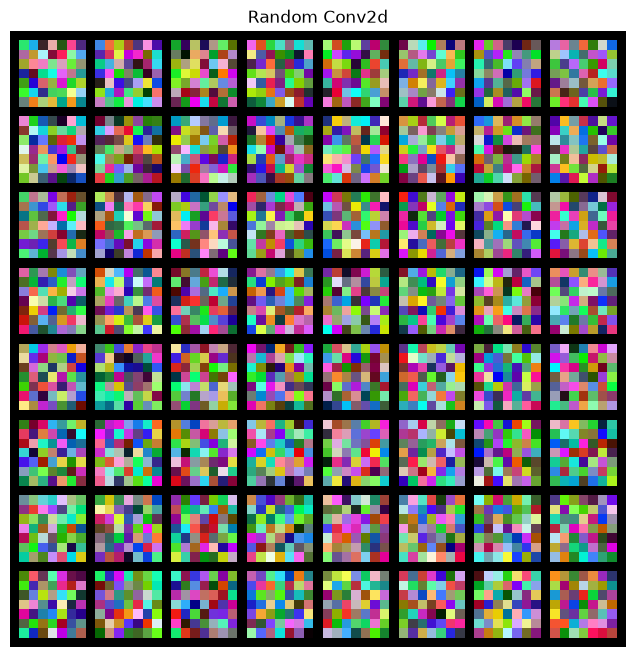

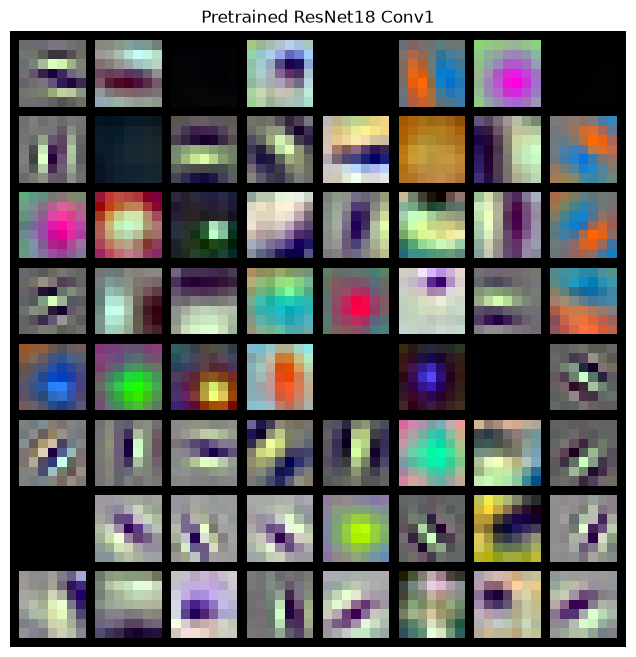

In [27]:
# === ЗАДАНИЕ 4.1 ===

from torchvision.models import resnet18, ResNet18_Weights

def plot_conv_filters(weight_tensor: torch.Tensor, title: str):
    """
    Визуализирует RGB-фильтры первого свёрточного слоя формы (Out, 3, kH, kW).
    """
    # Реализуйте функцию с использованием torchvision.utils.make_grid(
    #     weight_tensor.detach().cpu(), nrow=8, normalize=True, scale_each=True, padding=1
    # )
    return torchvision.utils.make_grid(weight_tensor.detach().cpu(), nrow=8, normalize=True, scale_each=True, padding=1)
    pass

# 1. Случайный слой
random_conv = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)

# 2. Предобученный слой из ResNet18 (если нет интернета для скачивания весов, используйте блок try/except)
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
pretrained_conv = resnet.conv1

# Постройте обе сетки фильтров рядом
for conv, title in zip([random_conv, pretrained_conv], ["Random Conv2d", "Pretrained ResNet18 Conv1"]):
    grid = plot_conv_filters(conv.weight, title)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis('off')
    plt.show()


### 4.2. Визуализация карт признаков (Feature Maps)

Пропустите одно изображение (из `shapes_dataset` или `cifar_dataset`, предварительно увеличив его до $128 \times 128$ через `transforms.Resize(128)`) через:
1. Случайно инициализированный слой `random_conv`
2. Обученный слой `pretrained_conv`

Отобразите первые 16 выходных каналов (Feature Maps) для каждого случая в виде сетки $4 \times 4$.

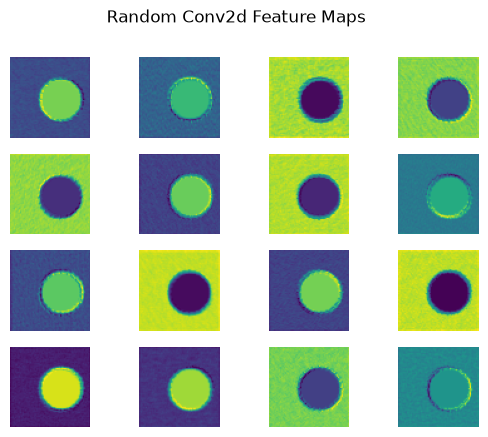

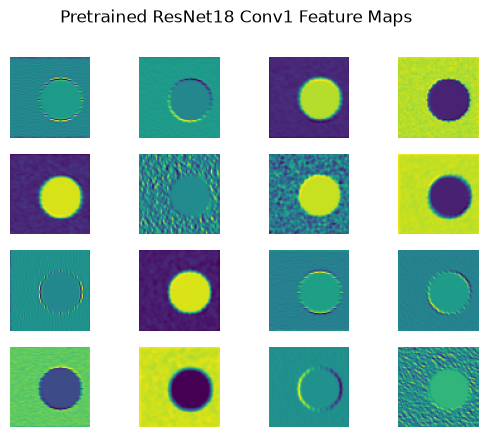

In [ ]:
# === ЗАДАНИЕ 4.2 ===

def visualize_feature_maps(image_tensor: torch.Tensor, conv_layer: nn.Conv2d, title: str, num_maps: int = 16):
    """
    Пропускает одно изображение (3, H, W) через conv_layer и отображает первые num_maps карт признаков.
    """
    # Реализуйте функцию
    # Подсказка:
    # 1. Добавьте batch dimension: x = image_tensor.unsqueeze(0)
    batch_input = image_tensor.unsqueeze(0)
    # 2. Сделайте прямой проход в блоке with torch.no_grad(): acts = conv_layer(x)
    with torch.no_grad():
        acts = conv_layer(batch_input)
    # 3. Отобразите первые num_maps каналов acts[0, :num_maps] на сетке 4x4 (cmap='viridis' или 'gray')
    for i in range(num_maps):
        plt.subplot(4, 4, i + 1)
        plt.imshow(acts[0, i].cpu(), cmap='viridis')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# Протестируйте на изображении из shapes_dataset или CIFAR-10
img_rgb, label = shapes_dataset[0]
img_resized = transforms.Resize((128, 128))(img_rgb)
visualize_feature_maps(img_resized, random_conv, "Random Conv2d Feature Maps", num_maps=16)
visualize_feature_maps(img_resized, pretrained_conv, "Pretrained ResNet18 Conv1 Feature Maps", num_maps=16)


---
## Задание 5. Исследование устойчивости детекторов границ к шуму

### Постановка эксперимента

Дифференцирование изображения (поиск границ) является некорректно поставленной задачей, чувствительной к высокочастотному шуму. Проведите эксперимент на фигурах из `ColorShapesDataset`:

1. Возьмите чистое изображение фигуры (`background_noise=1`) и переведите его в оттенки серого $I_0 \in [0, 1]$.
2. Добавляйте к нему гауссов шум $I_{\sigma} = \operatorname{clamp}(I_0 + \mathcal{N}(0, \sigma^2), 0, 1)$ для уровней $\sigma \in [0.0, 0.05, 0.10, 0.20, 0.30]$.
3. Для каждого уровня шума выделите границы тремя способами:
   - **Метод 1:** Оператор Собеля напрямую по зашумлённому изображению.
   - **Метод 2:** Оператор Лапласа напрямую по зашумлённому изображению.
   - **Метод 3 (Сглаживание + Собель):** Предварительное сглаживание гауссовым фильтром $5 \times 5$, а затем оператор Собеля.
4. Вычислите метрику качества выделения границ (например, косинусное сходство или корреляцию Пирсона между картой границ на зашумлённом изображении и эталонной картой границ на чистом изображении $\sigma=0$) и постройте график зависимости качества от $\sigma$.

### Вопросы для анализа

Ответьте в текстовой ячейке ниже:
1. Почему сумма элементов сглаживающего фильтра всегда равна $1$, а сумма элементов любого фильтра выделения границ (Собель, Лапласиан) равна $0$? Что произойдёт с однородным участком изображения, если сумма ядра не равна $1$ или $0$?
2. Почему оператор Лапласа (вторая производная) разрушается от шума значительно быстрее, чем оператор Собеля (первая производная)?
3. В чём преимущество разделения стандартной свёртки на `Depthwise` (`groups=C_in`) + `Pointwise` ($1 \times 1$ свёртка) в современных мобильных архитектурах (MobileNet, EfficientNet)?

In [18]:
# === ЗАДАНИЕ 5 (ИССЛЕДОВАНИЕ) ===

def make_gaussian_kernel_5x5() -> torch.Tensor:
    """Возвращает нормированное гауссово ядро 5x5."""
    k1d = torch.tensor([1., 4., 6., 4., 1.])
    k2d = torch.outer(k1d, k1d)
    return k2d / k2d.sum()

def edge_correlation(edge_clean: torch.Tensor, edge_noisy: torch.Tensor) -> float:
    """Вычисляет корреляцию между эталонной картой границ и картой на зашумлённом изображении."""
    a = edge_clean.flatten() - edge_clean.mean()
    b = edge_noisy.flatten() - edge_noisy.mean()
    return (torch.sum(a * b) / (torch.sqrt(torch.sum(a ** 2) * torch.sum(b ** 2)) + 1e-8)).item()

# Проведите эксперимент для разных уровней шума sigma_list = [0.0, 0.05, 0.1, 0.2, 0.3]
# Постройте визуальное сравнение и график падения корреляции для трёх методов


### Ответы на вопросы

1. ...
2. ...
3. ...

---

## Полезные ссылки

- [PyTorch: torch.nn.Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [PyTorch: torch.nn.functional.conv2d](https://pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html)
- [Визуализация геометрии свёрток (Convolution Arithmetic)](https://github.com/vdumoulin/conv_arithmetic)
- [CS231n: Convolutional Neural Networks for Visual Recognition](https://cs231n.github.io/convolutional-networks/)